# Week 3: Unsupervised Learning and Clustering Analysis
## Customer Segmentation Using K-Means

**Objective:** Segment customers into meaningful groups using unsupervised learning, visualize the clusters, and interpret their potential business value.

**Dataset:** Public Mall Customers dataset. Run cells from top to bottom. Interpretations should be based on the cluster summaries produced by your run; clusters are exploratory groups, not ground-truth customer types.

**Workflow:** load data → inspect and clean → select features → scale → choose cluster count → fit K-Means → visualize → profile clusters → export results.

## 1. Install required libraries
Run once if packages are missing.

In [1]:
%pip install pandas numpy matplotlib seaborn scikit-learn

Note: you may need to restart the kernel to use updated packages.


## 2. Import libraries and create an output folder

In [22]:
from pathlib import Path
import json
import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

sns.set_theme(style="whitegrid")
OUTPUT_DIR = Path.cwd() / "week3_outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print("Libraries imported. Output folder:", OUTPUT_DIR.resolve())

Libraries imported. Output folder: C:\Users\Tharun\Internship\Week 3 Task Unsupervised Learning and Clustering Analysis\week3_outputs


## 3. Load the dataset

The notebook tries public CSV links. If automatic loading fails, download a Mall Customers CSV from a public dataset source, place it beside this notebook, set `LOCAL_CSV_PATH = "Mall_Customers.csv"`, and rerun this cell. Expected fields include Gender, Age, Annual Income, and Spending Score.

In [23]:

import pandas as pd

LOCAL_CSV_PATH = None

DATA_URLS = [
    "https://raw.githubusercontent.com/gakudo-ai/open-datasets/refs/heads/main/Mall_Customers.csv",
    "https://raw.githubusercontent.com/MahimaSriK/Mall-Customer-Segmentation-Dataset/main/Mall_Customers.csv",
]

df = None
errors = []

if LOCAL_CSV_PATH:
    df = pd.read_csv(LOCAL_CSV_PATH)
else:
    for url in DATA_URLS:
        try:
            df = pd.read_csv(url)
            print("Loaded from:", url)
            break
        except Exception as exc:
            errors.append(f"{url}: {exc}")

if df is None:
    print("Dataset download failed.")
    print("Errors:", errors)
else:
    print("Dataset loaded successfully!")
    print("Dataset shape:", df.shape)
    print("Columns:", df.columns.tolist())
    display(df.head())


Loaded from: https://raw.githubusercontent.com/gakudo-ai/open-datasets/refs/heads/main/Mall_Customers.csv
Dataset loaded successfully!
Dataset shape: (200, 5)
Columns: ['CustomerID', 'Gender', 'Age', 'Annual Income (k$)', 'Spending Score (1-100)']


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


## 4. Inspect and clean the data

In [24]:
if df is None:
    raise ValueError("Dataset is not loaded. Follow the fallback instructions in Section 3.")

print("Shape:", df.shape)
print("Columns:", df.columns.tolist())
print("\nData types:")
display(df.dtypes.to_frame("data_type"))
print("\nMissing values:")
display(df.isna().sum().to_frame("missing_values"))
print("\nExact duplicate rows:", int(df.duplicated().sum()))
display(df.describe(include="all").T)

Shape: (200, 5)
Columns: ['CustomerID', 'Gender', 'Age', 'Annual Income (k$)', 'Spending Score (1-100)']

Data types:


,data_type
CustomerID,int64
Gender,str
Age,int64
Annual Income (k$),int64
Spending Score (1-100),int64



Missing values:


,missing_values
CustomerID,0
Gender,0
Age,0
Annual Income (k$),0
Spending Score (1-100),0



Exact duplicate rows: 0


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
CustomerID,200.0,NaN,NaN,NaN,100.5,57.879185,1.0,50.75,100.5,150.25,200.0
Gender,200,2,Female,112,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age,200.0,NaN,NaN,NaN,38.85,13.969007,18.0,28.75,36.0,49.0,70.0
Annual Income (k$),200.0,NaN,NaN,NaN,60.56,26.264721,15.0,41.5,61.5,78.0,137.0
Spending Score (1-100),200.0,NaN,NaN,NaN,50.2,25.823522,1.0,34.75,50.0,73.0,99.0


In [25]:
# Standardize common column-name variations.
rename_map = {}
for col in df.columns:
    n = col.strip().lower().replace("_", " ").replace("-", " ")
    if n in ["customerid", "customer id"]:
        rename_map[col] = "CustomerID"
    elif n == "gender":
        rename_map[col] = "Gender"
    elif n == "age":
        rename_map[col] = "Age"
    elif "annual income" in n:
        rename_map[col] = "Annual Income (k$)"
    elif "spending score" in n:
        rename_map[col] = "Spending Score (1-100)"
df = df.rename(columns=rename_map)

FEATURES = ["Age", "Annual Income (k$)", "Spending Score (1-100)"]
required = ["Gender"] + FEATURES
missing_cols = [c for c in required if c not in df.columns]
if missing_cols:
    raise ValueError(f"Expected columns not found: {missing_cols}. Check the dataset.")
analysis_df = df[required].copy()
for col in FEATURES:
    analysis_df[col] = pd.to_numeric(analysis_df[col], errors="coerce")
analysis_df = analysis_df.dropna(subset=required).reset_index(drop=True)
print("Rows available for analysis:", len(analysis_df))
display(analysis_df.head())

Rows available for analysis: 200


,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,Male,19,15,39
1,Male,21,15,81
2,Female,20,16,6
3,Female,23,16,77
4,Female,31,17,40


## 5. Explore the selected features

Age, annual income, and spending score are used for clustering. Gender is kept for later descriptive profiling but is not a clustering feature in this baseline model.

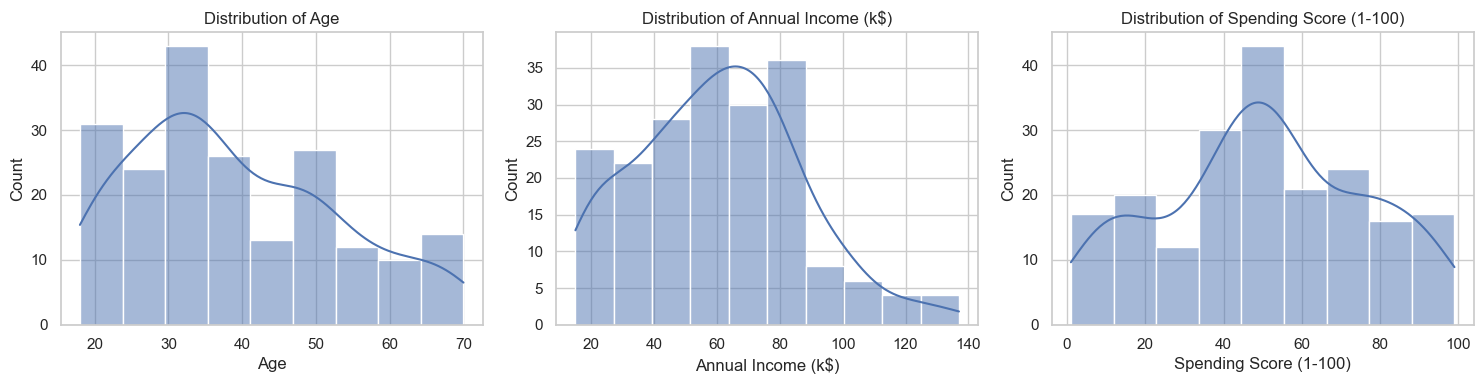

,Age,Annual Income (k$),Spending Score (1-100)
Age,1.000000,-0.012398,-0.327227
Annual Income (k$),-0.012398,1.000000,0.009903
Spending Score (1-100),-0.327227,0.009903,1.000000


In [26]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, FEATURES):
    sns.histplot(analysis_df[col], kde=True, ax=ax)
    ax.set_title(f"Distribution of {col}")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "feature_distributions.png", dpi=300, bbox_inches="tight")
plt.show()
display(analysis_df[FEATURES].corr())

## 6. Scale features

In [27]:
X = analysis_df[FEATURES].copy()
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
print("Feature scaling complete. Matrix shape:", X_scaled.shape)

Feature scaling complete. Matrix shape: (200, 3)


## 7. Choose the number of clusters

The Elbow Method examines how inertia changes as the cluster count increases. The Silhouette Score estimates cluster cohesion and separation. Use both plots and interpretability to choose a reasonable `k`.

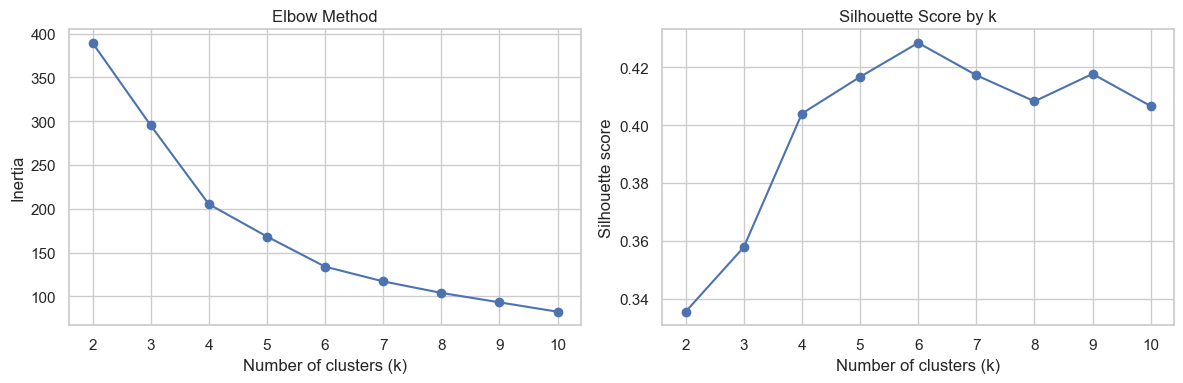

,k,inertia,silhouette_score
0,2,389.386189,0.335472
1,3,295.212246,0.357793
2,4,205.225147,0.403958
3,5,168.247580,0.416643
4,6,133.868421,0.428417
5,7,117.011555,0.417232
6,8,103.873292,0.408207
7,9,93.092891,0.417693
8,10,82.385154,0.406554


Highest silhouette score among tested values at k = 6


In [28]:
k_values = list(range(2, 11))
inertias, silhouettes = [], []
for k in k_values:
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = model.fit_predict(X_scaled)
    inertias.append(model.inertia_)
    silhouettes.append(silhouette_score(X_scaled, labels))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(k_values, inertias, marker="o")
axes[0].set(title="Elbow Method", xlabel="Number of clusters (k)", ylabel="Inertia")
axes[1].plot(k_values, silhouettes, marker="o")
axes[1].set(title="Silhouette Score by k", xlabel="Number of clusters (k)", ylabel="Silhouette score")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "cluster_selection_metrics.png", dpi=300, bbox_inches="tight")
plt.show()

score_table = pd.DataFrame({"k": k_values, "inertia": inertias, "silhouette_score": silhouettes})
display(score_table)
print("Highest silhouette score among tested values at k =", int(score_table.loc[score_table.silhouette_score.idxmax(), "k"]))

In [29]:

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import pandas as pd

comparison_results = []

for k in [5, 6]:
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    labels = model.fit_predict(X_scaled)

    comparison_results.append({
        "Number of Clusters": k,
        "Silhouette Score": round(
            silhouette_score(X_scaled, labels), 4
        ),
        "Inertia": round(model.inertia_, 2)
    })

comparison_df = pd.DataFrame(comparison_results)
display(comparison_df)


,Number of Clusters,Silhouette Score,Inertia
0,5,0.4166,168.25
1,6,0.4284,133.87


## 8. Fit the final K-Means model

Start with `FINAL_K = 5`, then review the Elbow and Silhouette plots above. Change this value if the metrics and segment interpretability suggest another choice. Cluster numbers are arbitrary identifiers, not rankings.

In [30]:
FINAL_K = 5
kmeans = KMeans(n_clusters=FINAL_K, random_state=42, n_init=10)
analysis_df["Cluster"] = kmeans.fit_predict(X_scaled)
final_silhouette = silhouette_score(X_scaled, analysis_df["Cluster"])
print("K-Means fitted. Selected k:", FINAL_K)
print("Silhouette score:", round(final_silhouette, 4))
display(analysis_df["Cluster"].value_counts().sort_index().rename("customers").to_frame())

K-Means fitted. Selected k: 5
Silhouette score: 0.4166


,customers
Cluster,
0,20
1,54
2,40
3,39
4,47


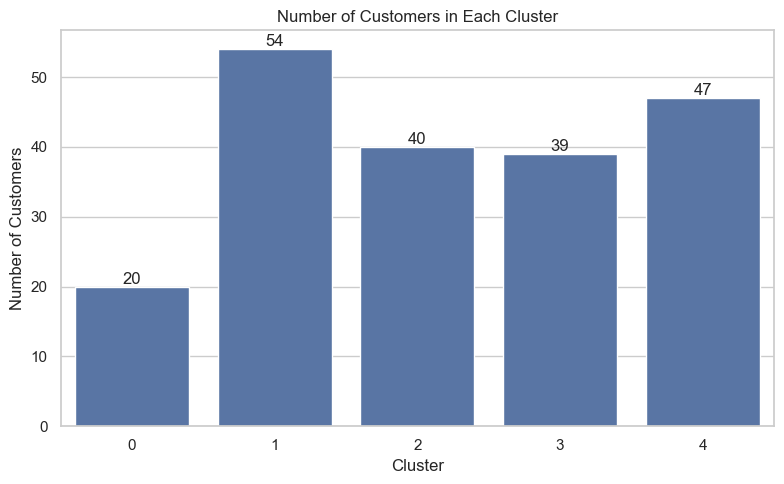

In [31]:

cluster_counts = (
    analysis_df["Cluster"].value_counts().sort_index()
)

plt.figure(figsize=(8, 5))

ax = sns.barplot(
    x=cluster_counts.index,
    y=cluster_counts.values
)

for container in ax.containers:
    ax.bar_label(container)

plt.title("Number of Customers in Each Cluster")
plt.xlabel("Cluster")
plt.ylabel("Number of Customers")
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "cluster_sizes.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


## 9. Visualize the clusters

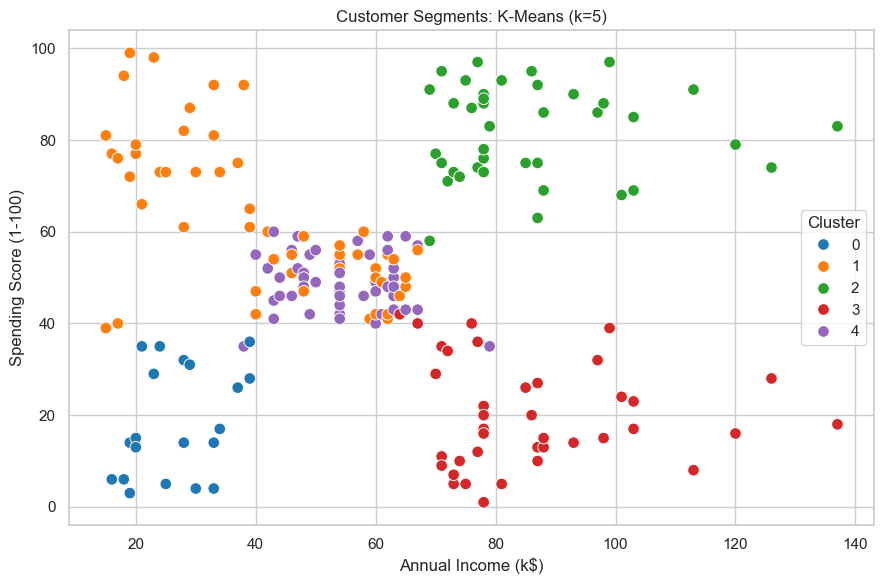

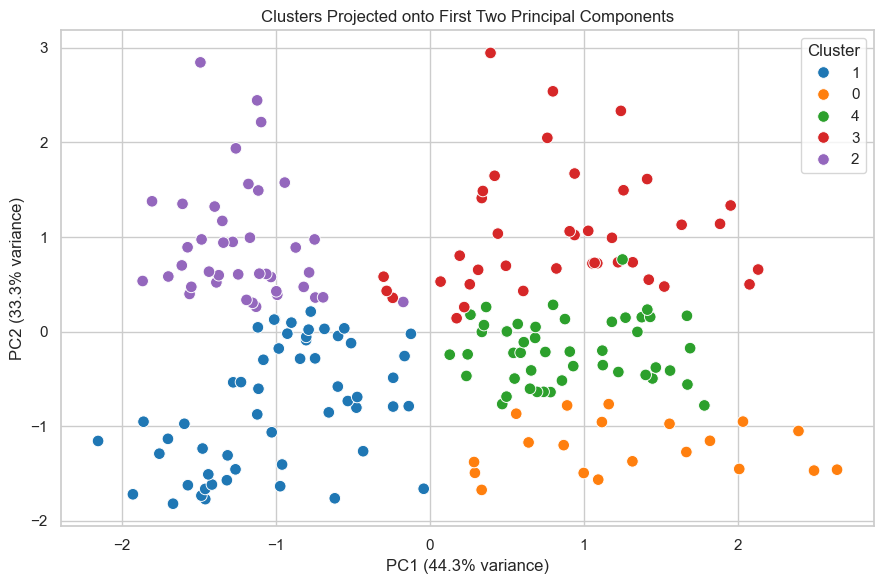

Variance explained by first two PCs: 0.7757


In [32]:
plt.figure(figsize=(9, 6))
sns.scatterplot(data=analysis_df, x="Annual Income (k$)", y="Spending Score (1-100)",
                hue="Cluster", palette="tab10", s=70)
plt.title(f"Customer Segments: K-Means (k={FINAL_K})")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "clusters_income_spending.png", dpi=300, bbox_inches="tight")
plt.show()

pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)
pca_df = pd.DataFrame({"PC1": X_pca[:, 0], "PC2": X_pca[:, 1],
                       "Cluster": analysis_df["Cluster"].astype(str)})
plt.figure(figsize=(9, 6))
sns.scatterplot(data=pca_df, x="PC1", y="PC2", hue="Cluster", palette="tab10", s=70)
plt.title("Clusters Projected onto First Two Principal Components")
plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}% variance)")
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}% variance)")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "clusters_pca_projection.png", dpi=300, bbox_inches="tight")
plt.show()
print("Variance explained by first two PCs:", round(pca.explained_variance_ratio_.sum(), 4))

## 10. Profile and interpret the clusters
Use the actual cluster profile table to describe each segment. Name clusters only after reviewing their observed averages.

In [33]:
cluster_profile = analysis_df.groupby("Cluster").agg(
    customer_count=("Cluster", "size"),
    mean_age=("Age", "mean"),
    mean_annual_income=("Annual Income (k$)", "mean"),
    mean_spending_score=("Spending Score (1-100)", "mean"),
    median_age=("Age", "median"),
    median_annual_income=("Annual Income (k$)", "median"),
    median_spending_score=("Spending Score (1-100)", "median")
).round(2)
cluster_profile["share_percent"] = (cluster_profile.customer_count / len(analysis_df) * 100).round(2)
display(cluster_profile)
display(pd.crosstab(analysis_df["Cluster"], analysis_df["Gender"], normalize="index").round(3))

,customer_count,mean_age,mean_annual_income,mean_spending_score,median_age,median_annual_income,median_spending_score,share_percent
Cluster,,,,,,,,
0,20,46.25,26.75,18.35,47.0,26.5,14.5,10.0
1,54,25.19,41.09,62.24,24.0,40.0,58.0,27.0
2,40,32.88,86.10,81.53,32.0,78.5,83.0,20.0
3,39,39.87,86.10,19.36,41.0,78.0,17.0,19.5
4,47,55.64,54.38,48.85,54.0,54.0,48.0,23.5


Gender,Female,Male
Cluster,,
0,0.600,0.400
1,0.593,0.407
2,0.550,0.450
3,0.487,0.513
4,0.574,0.426


,Age,Annual Income (k$),Spending Score (1-100)
Cluster,,,
0,46.25,26.75,18.35
1,25.19,41.09,62.24
2,32.88,86.10,81.53
3,39.87,86.10,19.36
4,55.64,54.38,48.85


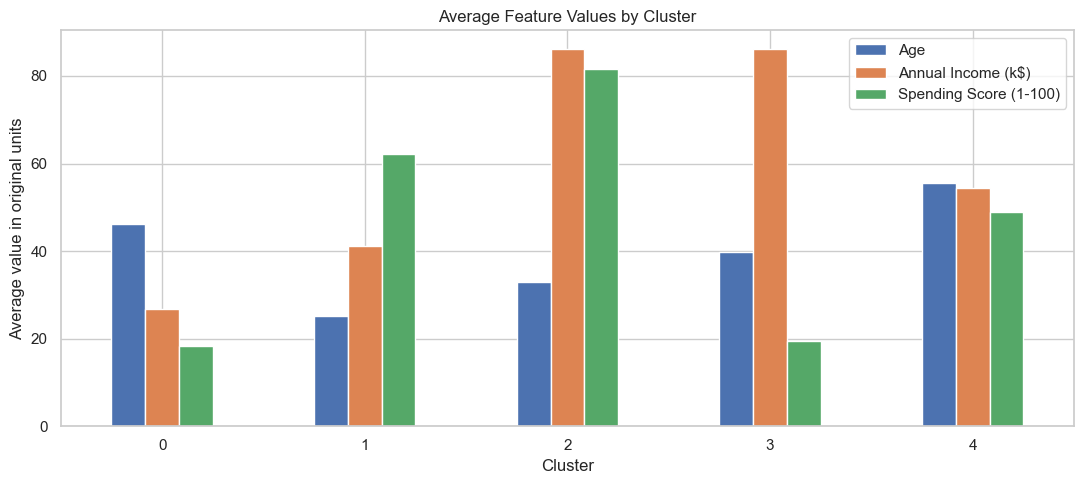

In [34]:
profile_means = analysis_df.groupby("Cluster")[FEATURES].mean().round(2)
display(profile_means)
profile_means.plot(kind="bar", figsize=(11, 5))
plt.title("Average Feature Values by Cluster")
plt.xlabel("Cluster")
plt.ylabel("Average value in original units")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "cluster_profile_means.png", dpi=300, bbox_inches="tight")
plt.show()

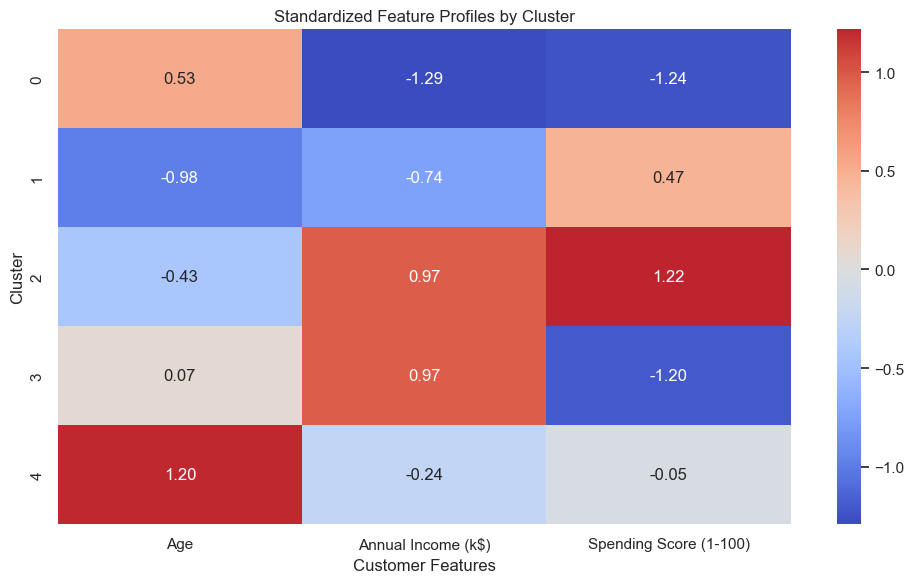

In [35]:

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

scaled_features = pd.DataFrame(
    X_scaled,
    columns=FEATURES
)

scaled_features["Cluster"] = (
    analysis_df["Cluster"].values
)

cluster_means_scaled = (
    scaled_features.groupby("Cluster")[FEATURES].mean()
)

plt.figure(figsize=(10, 6))

sns.heatmap(
    cluster_means_scaled,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Standardized Feature Profiles by Cluster")
plt.xlabel("Customer Features")
plt.ylabel("Cluster")
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "standardized_cluster_profiles.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


## 11. Optional comparison: hierarchical clustering
Agglomerative clustering provides an alternative method. Its cluster labels do not necessarily correspond to K-Means labels.

In [36]:
hierarchical = AgglomerativeClustering(n_clusters=FINAL_K, linkage="ward")
hier_labels = hierarchical.fit_predict(X_scaled)
comparison = pd.DataFrame({
    "Algorithm": ["K-Means", "Agglomerative Hierarchical"],
    "Clusters": [FINAL_K, FINAL_K],
    "Silhouette Score": [
        silhouette_score(X_scaled, analysis_df["Cluster"]),
        silhouette_score(X_scaled, hier_labels)
    ]
})
display(comparison)

,Algorithm,Clusters,Silhouette Score
0,K-Means,5,0.416643
1,Agglomerative Hierarchical,5,0.390028


## 12. Export tables and results

In [38]:
analysis_df.to_csv(OUTPUT_DIR / "customer_clusters.csv", index=False)
cluster_profile.to_csv(OUTPUT_DIR / "cluster_profile.csv")
score_table.to_csv(OUTPUT_DIR / "cluster_selection_scores.csv", index=False)
comparison.to_csv(OUTPUT_DIR / "algorithm_comparison.csv", index=False)
comparison_df.to_csv(OUTPUT_DIR / "k5_vs_k6_comparison.csv", index=False)

summary = {
    "dataset_rows_used": int(len(analysis_df)),
    "features_used": FEATURES,
    "selected_k": int(FINAL_K),
    "kmeans_silhouette_score": float(final_silhouette),
    "cluster_sizes": {str(int(k)): int(v) for k, v in analysis_df["Cluster"].value_counts().sort_index().items()},
    "pca_variance_explained_first_two_components": float(pca.explained_variance_ratio_.sum())
}
with open(OUTPUT_DIR / "clustering_summary.json", "w", encoding="utf-8") as f:
    json.dump(summary, f, indent=2)
print("Results exported to:", OUTPUT_DIR.resolve())
print("Files:", sorted(p.name for p in OUTPUT_DIR.iterdir()))

Results exported to: C:\Users\Tharun\Internship\Week 3 Task Unsupervised Learning and Clustering Analysis\week3_outputs
Files: ['algorithm_comparison.csv', 'cluster_profile.csv', 'cluster_profile_means.png', 'cluster_selection_metrics.png', 'cluster_selection_scores.csv', 'cluster_sizes.png', 'clustering_summary.json', 'clusters_income_spending.png', 'clusters_pca_projection.png', 'customer_clusters.csv', 'feature_distributions.png', 'k5_vs_k6_comparison.csv', 'standardized_cluster_profiles.png']


## 13. Interpretation and limitations for the report

For each cluster, report its size and percentage, average age, average income, average spending score, an evidence-based description, and a possible business action. For example, retention campaigns or targeted offers may be considered if supported by the cluster profile.

**Limitations:** K-Means requires a chosen cluster count, is sensitive to scaling and outliers, and tends to favor compact, roughly spherical groups. Results depend on the features and dataset selected. Cluster associations are descriptive and do not establish causation.

## Conclusion
This notebook demonstrates data inspection, preprocessing, feature scaling, choosing a cluster count, K-Means clustering, visualization, cluster profiling, an optional hierarchical comparison, and exporting results for documentation.